# Post-drought forest dieback in Sardinia: where should foresters inspect first?

**Earth Observation AI Engineer · home assignment**

In summer 2024 southern and eastern Sardinia went through an extreme drought and heatwave. The Regional Government reported a fast-spreading dieback of cork-oak and holm-oak woods and Mediterranean scrub over thousands of hectares, monitored with satellite imagery, drones and field checks in Gallura, Nuorese, Ogliastra, Baronia and Sarrabus (Delibera RAS n. 31/7, 28 Aug 2024).

This notebook turns Sentinel-2 imagery into a ranked list of forest areas to inspect in the Sette Fratelli massif (Sarrabus, SE Sardinia).

## 1. Decision question and user

- **User:** the regional forest service (Agenzia Forestas / Corpo Forestale), planning field surveys after the drought.
- **Decision:** *Which forest areas should field teams inspect first for dieback, i.e. canopy that dried out in 2024 **and did not recover** in 2025?*
- **Why recovery matters:** in a drought year almost every Mediterranean evergreen canopy loses water and some leaves, then recovers. An alert on the 2024 drop alone would flag almost the whole forest. Persistent decline (no recovery the following year) is the signal linked to dieback and later mortality (Lloret et al., 2011; DeSoto et al., 2020), and is the same resistance → recovery logic used with Sentinel-2 after the 2018 drought in Switzerland (Sturm et al., 2022).

## 2. Data and backend choices

| Choice | Decision | Why |
|---|---|---|
| Backend | **Microsoft Planetary Computer** (STAC API) | No account needed: anyone can rerun the notebook. Real pixels are read from Cloud-Optimised GeoTIFFs (only the AOI window is downloaded). ESA WorldCover is in the same catalogue. |
| Collection | **Sentinel-2 L2A** | 10–20 m, 5-day revisit, surface reflectance (atmospherically corrected), SWIR bands B11/B12 needed for canopy water. Landsat is coarser (30 m) and less frequent; Sentinel-1 does not measure leaf water directly. |
| Season | **July–September** of each year, 2019–2025 | Peak of the dry season, when drought stress is visible; same phenological window every year so years are comparable; very few clouds in Sardinian summers. |
| Baseline | **2019–2023** summers | Five pre-event summers, including a dry (2021) and a wet (2022) one, to estimate normal inter-annual variability. |
| Forest mask | **ESA WorldCover 2021**, class 10 (tree cover) | Open, 10 m, global, same catalogue. |

All processing code lives in `src/pipeline.py`. The notebook and the MCP server (bonus A) call the same functions.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import pipeline as pl

# Area of interest: Sette Fratelli massif, Sarrabus (lon_min, lat_min, lon_max, lat_max)
AOI = (9.33, 39.19, 9.52, 39.33)
YEARS = list(range(2019, 2026))
BASE_YEARS = [2019, 2020, 2021, 2022, 2023]
SEASON = ("07-01", "09-30")
RES = 20  # metres; native resolution of B8A/B11/B12

In [2]:
import folium

lon0, lat0, lon1, lat1 = AOI
m = folium.Map(location=[(lat0 + lat1) / 2, (lon0 + lon1) / 2], zoom_start=10, tiles="OpenStreetMap")
folium.Rectangle([[lat0, lon0], [lat1, lon1]], color="red", fill=False, tooltip="AOI").add_to(m)
m

## 3. Ingest: real Sentinel-2 L2A acquisitions

We query the STAC catalogue for every summer and keep scenes with tile-level cloud cover below 20 %.

Some acquisition dates appear twice: ESA reprocessed them with a newer *processing baseline*. We keep one item per date, the most recent baseline (`pl.dedup_by_date`).

In [3]:
scenes = {y: pl.search_scenes(AOI, f"{y}-{SEASON[0]}", f"{y}-{SEASON[1]}") for y in YEARS}
summary = pd.DataFrame({
    "acquisitions": {y: len(v) for y, v in scenes.items()},
    "tiles": {y: ", ".join(sorted({it.properties["s2:mgrs_tile"] for it in v})) for y, v in scenes.items()},
})
summary.loc["total"] = [summary.acquisitions.sum(), ""]
summary

,acquisitions,tiles
2019,13,32SNJ
2020,15,32SNJ
2021,9,32SNJ
2022,13,32SNJ
2023,15,32SNJ
2024,12,32SNJ
2025,21,32SNJ
total,98,


In [4]:
pl.scenes_table(scenes[2024])

,date,tile,cloud_cover_%,baseline,id
0,2024-07-11,32SNJ,0.0,05.10,S2B_MSIL2A_20240711T100559_R022_T32SNJ_2024071...
1,2024-07-16,32SNJ,0.0,05.10,S2A_MSIL2A_20240716T100601_R022_T32SNJ_2024071...
2,2024-07-21,32SNJ,0.3,05.10,S2B_MSIL2A_20240721T100559_R022_T32SNJ_2024072...
3,2024-07-26,32SNJ,0.2,05.11,S2A_MSIL2A_20240726T100601_R022_T32SNJ_2024072...
4,2024-07-31,32SNJ,0.0,05.11,S2B_MSIL2A_20240731T100559_R022_T32SNJ_2024073...
5,2024-08-05,32SNJ,4.7,05.11,S2A_MSIL2A_20240805T100601_R022_T32SNJ_2024080...
6,2024-08-10,32SNJ,1.6,05.11,S2B_MSIL2A_20240810T100559_R022_T32SNJ_2024081...
7,2024-08-25,32SNJ,0.0,05.11,S2A_MSIL2A_20240825T100551_R022_T32SNJ_2024082...
8,2024-08-30,32SNJ,0.1,05.11,S2B_MSIL2A_20240830T100559_R022_T32SNJ_2024083...
9,2024-09-09,32SNJ,5.8,05.11,S2B_MSIL2A_20240909T100559_R022_T32SNJ_2024090...


## 4. Preprocessing

1. **Scaling and offset.** L2A digital numbers are reflectance × 10 000. Since processing baseline 04.00 (25 Jan 2022) a +1000 offset is added. We remove it before any index: normalised-difference indices are *not* invariant to an additive offset, so mixing baselines without correction would create a fake 2022 break in the time series.
2. **Cloud / quality masking with the Scene Classification Layer (SCL).** We keep only *vegetation* (4) and *not-vegetated* (5) pixels. Clouds (8, 9), cirrus (10), cloud shadows (3), water (6), snow (11), saturated/defective and no-data pixels are dropped. Using a whitelist rather than a blacklist is conservative: unknown or unclassified pixels (7) are excluded too.
3. **Resolution and CRS.** Everything is resampled on one 20 m grid in UTM 32N (EPSG:32632), the native CRS of the tile, so no reprojection of the original pixels is needed. 20 m is the native resolution of B8A/B11/B12, which drive the moisture indices.
4. **Temporal handling.** One median composite per summer (July–September). The median is robust to residual clouds and haze missed by SCL and to single anomalous dates. One value per year also matches the question: how did this summer compare with normal summers?

Below, one 2024 acquisition before and after masking.

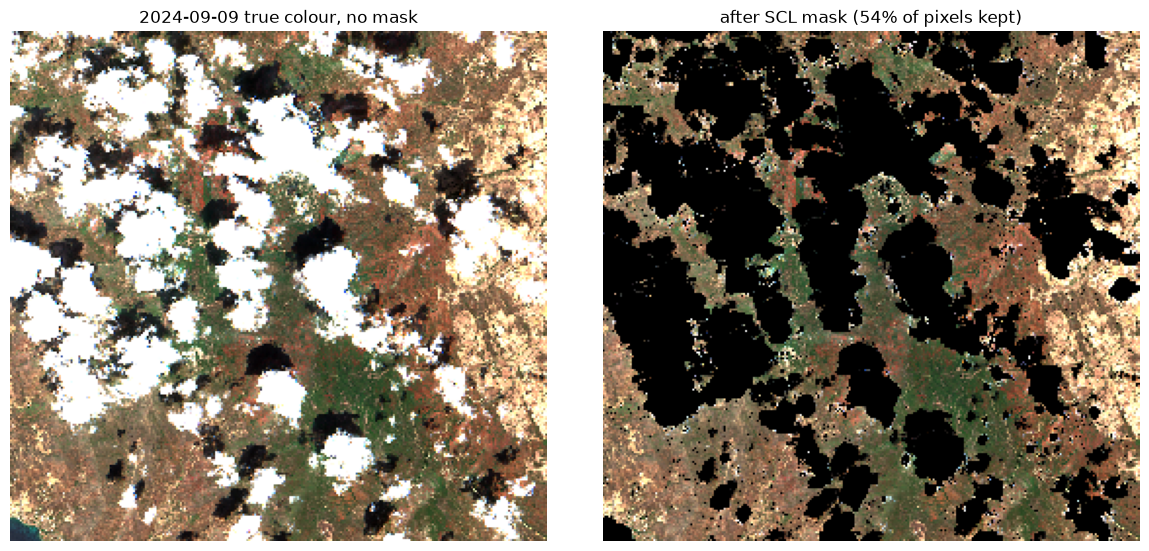

In [5]:
item = max(scenes[2024], key=lambda it: it.properties["eo:cloud_cover"])  # cloudiest 2024 scene, to show the mask
raw = pl.load_reflectance([item], AOI, resolution=60, mask=False).isel(time=0).compute()
msk = pl.load_reflectance([item], AOI, resolution=60, mask=True).isel(time=0).compute()

fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
ax[0].imshow(pl.to_rgb(raw)); ax[0].set_title(f"{item.datetime.date()} true colour, no mask")
ax[1].imshow(pl.to_rgb(msk.fillna(0))); ax[1].set_title(f"after SCL mask ({float(msk.valid.mean()):.0%} of pixels kept)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

The scene's tile-level metadata says 5.8 % cloud cover, yet over our AOI the SCL mask removes about half of the pixels (clouds **and** their shadows). Two consequences:

- `eo:cloud_cover` is only a coarse pre-filter. Masking has to be per pixel.
- A seasonal **median** is needed: on any single date part of the forest is missing, but across the 12 summer dates of 2024 almost every pixel has several clear observations.

Even in this partly cloudy image, the September 2024 canopy already looks brown-red in many stands, the visual signature we will quantify with the indices.